In [ ]:
# %% [1. UNIVERSAL IMPORTS]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.datasets import load_iris, load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler

from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.svm import SVC, SVR
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB

from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay,
    r2_score, mean_squared_error, mean_absolute_error,
    silhouette_score, davies_bouldin_score
)

sns.set_theme(style='whitegrid')


In [2]:
# %% [2. DATA LOADING & SPLIT - SUPERVISED]
# --- Option A: Built-in Dataset ---
data = load_iris(as_frame=True)
df = data.frame
X = data.data
y = data.target

# --- Option B: CSV Load ---
# df = pd.read_csv('dataset.csv')
# df = df.dropna()
# df = pd.get_dummies(df, drop_first=True)
# TARGET = 'target_column'
# X = df.drop(columns=[TARGET])
# y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Train shape: {X_train.shape} | Test shape: {X_test.shape}")


Train shape: (120, 4) | Test shape: (30, 4)


--- Dataset Information ---
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB
None

--- Descriptive Statistics ---


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


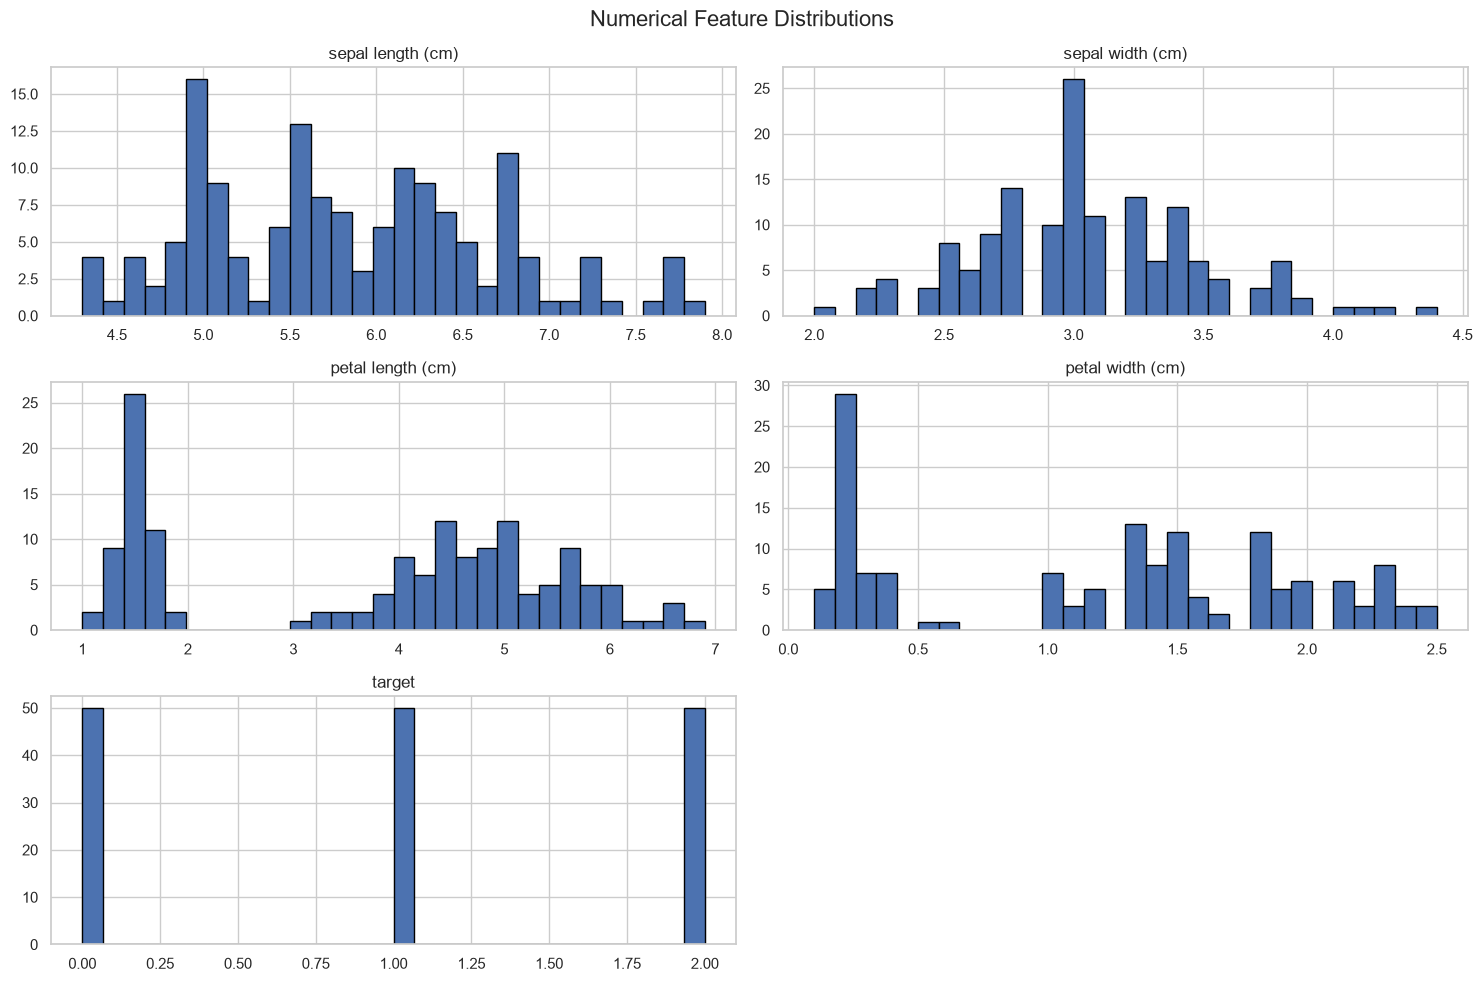

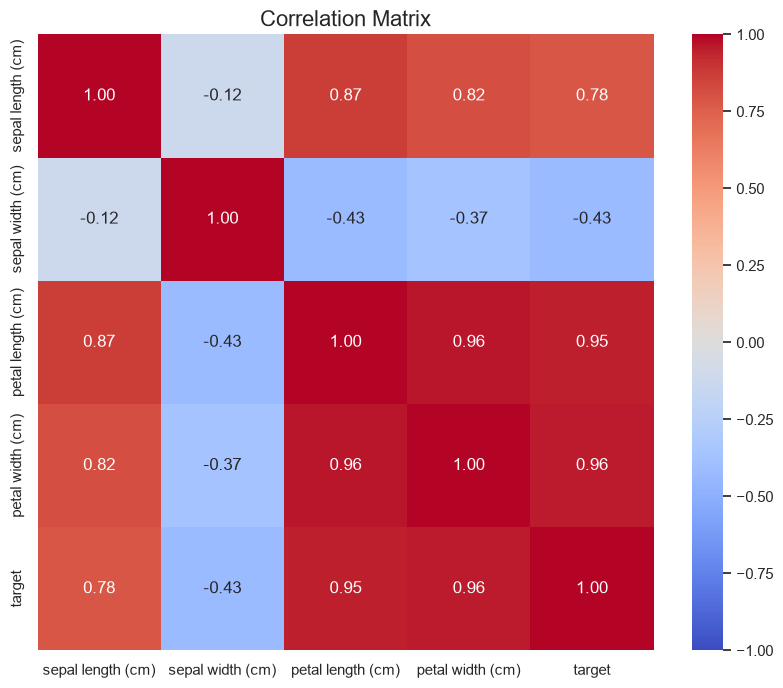

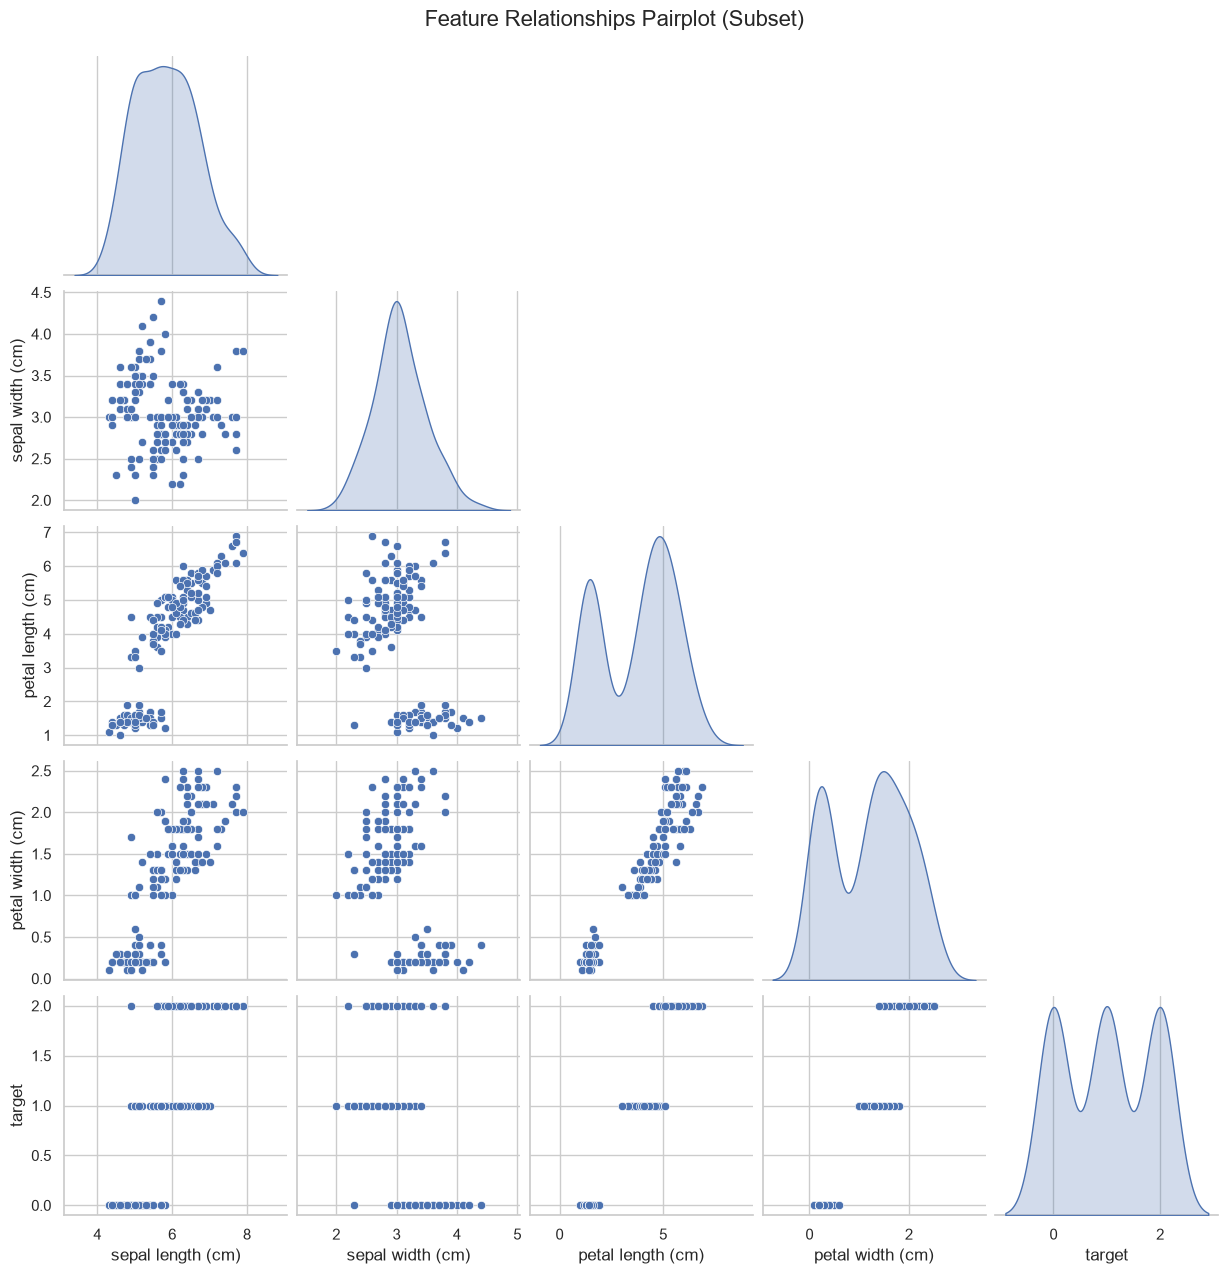

In [10]:
# Elaborate Exploratory Data Analysis (EDA) - Generic
print("--- Dataset Information ---")
print(df.info())

print("\n--- Descriptive Statistics ---")
display(df.describe())

# Select only numerical columns to prevent plotting errors
numeric_cols = df.select_dtypes(include=[np.number]).columns

if len(numeric_cols) > 0:
    # 1. Plotting distributions for numerical features
    df[numeric_cols].hist(bins=30, figsize=(15, 10), edgecolor='black')
    plt.suptitle("Numerical Feature Distributions", fontsize=16)
    plt.tight_layout()
    plt.show()

    # 2. Correlation Matrix Heatmap
    plt.figure(figsize=(10, 8))
    corr_matrix = df[numeric_cols].corr()
    sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', square=True, vmin=-1, vmax=1)
    plt.title("Correlation Matrix", fontsize=16)
    plt.show()

    # 3. Pairplot for feature relationships
    # Subsetting to a maximum of 5 columns to prevent extremely slow rendering/clutter
    cols_to_plot = numeric_cols[:5]
    sns.pairplot(df[cols_to_plot], corner=True, diag_kind='kde')
    plt.suptitle("Feature Relationships Pairplot (Subset)", y=1.02, fontsize=16)
    plt.show()
else:
    print("No numerical columns found for plotting.")

In [4]:
# %% [4. FEATURE SCALING]
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# X_scaled = scaler.fit_transform(X)


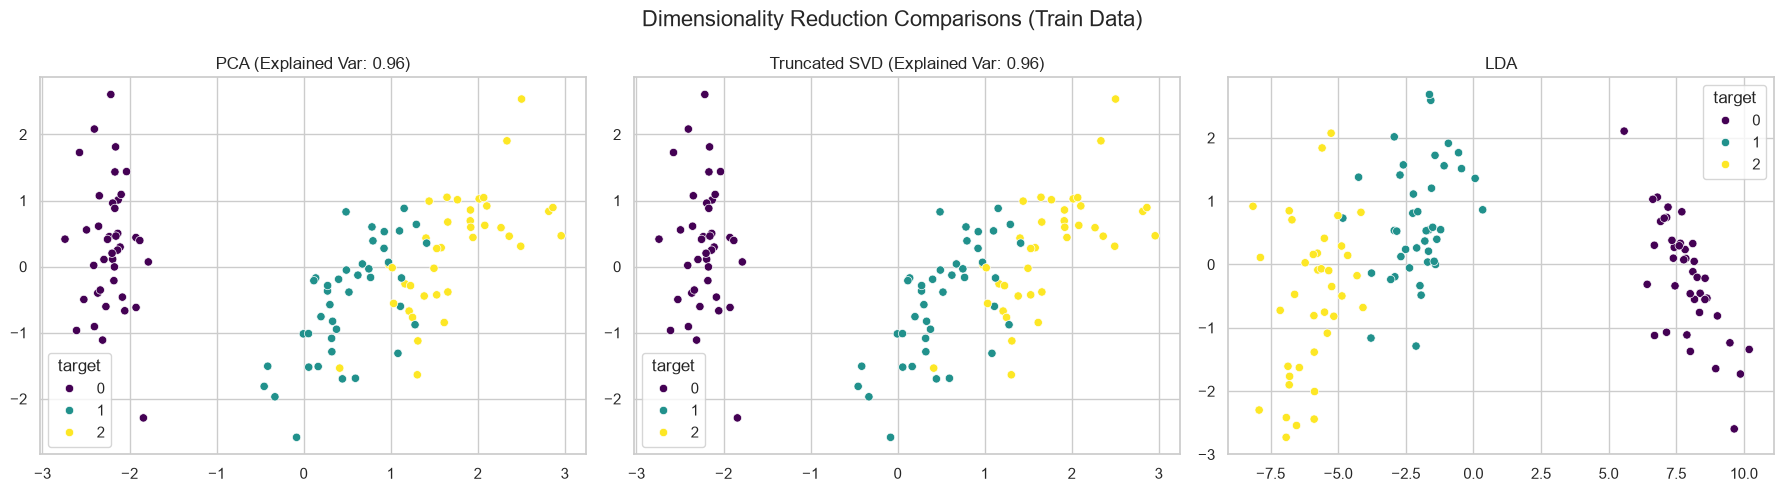

In [5]:
# %% [5. DIMENSIONALITY REDUCTION]
# 1. Principal Component Analysis (PCA) - Unsupervised
pca = PCA(n_components=2)
X_pca_train = pca.fit_transform(X_train_scaled)
X_pca_test = pca.transform(X_test_scaled)

# 2. Truncated Singular Value Decomposition (SVD) - Unsupervised
svd = TruncatedSVD(n_components=2)
X_svd_train = svd.fit_transform(X_train_scaled)
X_svd_test = svd.transform(X_test_scaled)

# 3. Linear Discriminant Analysis (LDA) - Supervised
# Note: LDA maximum components is bounded by (n_classes - 1)
lda_comp = min(2, len(np.unique(y_train)) - 1)
lda = LDA(n_components=lda_comp)
X_lda_train = lda.fit_transform(X_train_scaled, y_train)
X_lda_test = lda.transform(X_test_scaled)

# Visualizing the reduced dimensional spaces
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# PCA Plot
sns.scatterplot(x=X_pca_train[:, 0], y=X_pca_train[:, 1], hue=y_train, palette='viridis', ax=axes[0])
axes[0].set_title(f'PCA (Explained Var: {pca.explained_variance_ratio_.sum():.2f})')

# SVD Plot
sns.scatterplot(x=X_svd_train[:, 0], y=X_svd_train[:, 1], hue=y_train, palette='viridis', ax=axes[1])
axes[1].set_title(f'Truncated SVD (Explained Var: {svd.explained_variance_ratio_.sum():.2f})')

# LDA Plot (Handling 1D vs 2D gracefully for binary targets)
if X_lda_train.shape[1] == 1:
    sns.scatterplot(x=X_lda_train[:, 0], y=np.zeros_like(X_lda_train[:, 0]), hue=y_train, palette='viridis', ax=axes[2])
    axes[2].set_yticks([])
else:
    sns.scatterplot(x=X_lda_train[:, 0], y=X_lda_train[:, 1], hue=y_train, palette='viridis', ax=axes[2])
axes[2].set_title('LDA')

plt.suptitle('Dimensionality Reduction Comparisons (Train Data)', fontsize=16)
plt.tight_layout()
plt.show()
